In [1]:
import pandas as pd
import numpy as np
import time

from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline
from sklearn.metrics import accuracy_score

In [2]:
# Load Breast Cancer Wisconsin dataset
data = load_breast_cancer()

# Create feature matrix and target variable
X = pd.DataFrame(data.data, columns=data.feature_names)
y = data.target

# Display dataset information
print("Dataset loaded successfully")
print("Number of samples:", X.shape[0])
print("Number of original features:", X.shape[1])
print("Target classes:", data.target_names)

# Display first five records
X.head()

Dataset loaded successfully
Number of samples: 569
Number of original features: 30
Target classes: ['malignant' 'benign']


,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,...,worst radius,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension
0,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,0.07871,...,25.38,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890
1,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,0.05667,...,24.99,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902
2,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,0.05999,...,23.57,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758
3,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,0.2597,0.09744,...,14.91,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300
4,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,0.1809,0.05883,...,22.54,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678


In [3]:
# Split data into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training samples:", X_train.shape[0])
print("Testing samples:", X_test.shape[0])

Training samples: 455
Testing samples: 114


In [4]:
# Create a pipeline for standardization and logistic regression
original_model = Pipeline([
    ('scaler', StandardScaler()),
    ('classifier', LogisticRegression(max_iter=5000))
])

# Measure training time
start_time = time.time()

original_model.fit(X_train, y_train)

original_time = time.time() - start_time

# Make predictions
y_pred_original = original_model.predict(X_test)

# Calculate accuracy
original_accuracy = accuracy_score(y_test, y_pred_original)

print("Original Dataset Results")
print("Number of features:", X_train.shape[1])
print("Classification Accuracy:", round(original_accuracy * 100, 2), "%")
print("Training Time:", round(original_time, 5), "seconds")

Original Dataset Results
Number of features: 30
Classification Accuracy: 98.25 %
Training Time: 0.24258 seconds


In [5]:
# Create a PCA pipeline
pca_model = Pipeline([
    ('scaler', StandardScaler()),
    ('pca', PCA(n_components=10)),
    ('classifier', LogisticRegression(max_iter=5000))
])

# Measure training time
start_time = time.time()

pca_model.fit(X_train, y_train)

pca_time = time.time() - start_time

# Make predictions
y_pred_pca = pca_model.predict(X_test)

# Calculate accuracy
pca_accuracy = accuracy_score(y_test, y_pred_pca)

print("PCA Results")
print("Original features:", X_train.shape[1])
print("Reduced features:", 10)
print("Classification Accuracy:", round(pca_accuracy * 100, 2), "%")
print("Training Time:", round(pca_time, 5), "seconds")

PCA Results
Original features: 30
Reduced features: 10
Classification Accuracy: 97.37 %
Training Time: 0.08199 seconds


In [6]:
# Create an LDA pipeline
lda_model = Pipeline([
    ('scaler', StandardScaler()),
    ('lda', LinearDiscriminantAnalysis(n_components=1)),
    ('classifier', LogisticRegression(max_iter=5000))
])

# Measure training time
start_time = time.time()

lda_model.fit(X_train, y_train)

lda_time = time.time() - start_time

# Make predictions
y_pred_lda = lda_model.predict(X_test)

# Calculate accuracy
lda_accuracy = accuracy_score(y_test, y_pred_lda)

print("LDA Results")
print("Original features:", X_train.shape[1])
print("Reduced features:", 1)
print("Classification Accuracy:", round(lda_accuracy * 100, 2), "%")
print("Training Time:", round(lda_time, 5), "seconds")

LDA Results
Original features: 30
Reduced features: 1
Classification Accuracy: 97.37 %
Training Time: 0.07699 seconds


In [7]:
# Get the fitted PCA object
pca = pca_model.named_steps['pca']

# Calculate explained variance
explained_variance = pca.explained_variance_ratio_

print("Explained variance ratio of each component:")
print(np.round(explained_variance, 4))

print(
    "Total variance retained:",
    round(np.sum(explained_variance) * 100, 2),
    "%"
)

Explained variance ratio of each component:
[0.4441 0.1894 0.0954 0.0672 0.0552 0.0393 0.0218 0.0158 0.0128 0.0115]
Total variance retained: 95.27 %


In [8]:
print("FINAL OBSERVATION")
print("-" * 50)

print(
    f"Original Dataset: {X_train.shape[1]} features, "
    f"{original_accuracy * 100:.2f}% accuracy, "
    f"{original_time:.5f} seconds"
)

print(
    f"PCA: 10 features, "
    f"{pca_accuracy * 100:.2f}% accuracy, "
    f"{pca_time:.5f} seconds"
)

print(
    f"LDA: 1 feature, "
    f"{lda_accuracy * 100:.2f}% accuracy, "
    f"{lda_time:.5f} seconds"
)

print("-" * 50)

FINAL OBSERVATION
--------------------------------------------------
Original Dataset: 30 features, 98.25% accuracy, 0.24258 seconds
PCA: 10 features, 97.37% accuracy, 0.08199 seconds
LDA: 1 feature, 97.37% accuracy, 0.07699 seconds
--------------------------------------------------


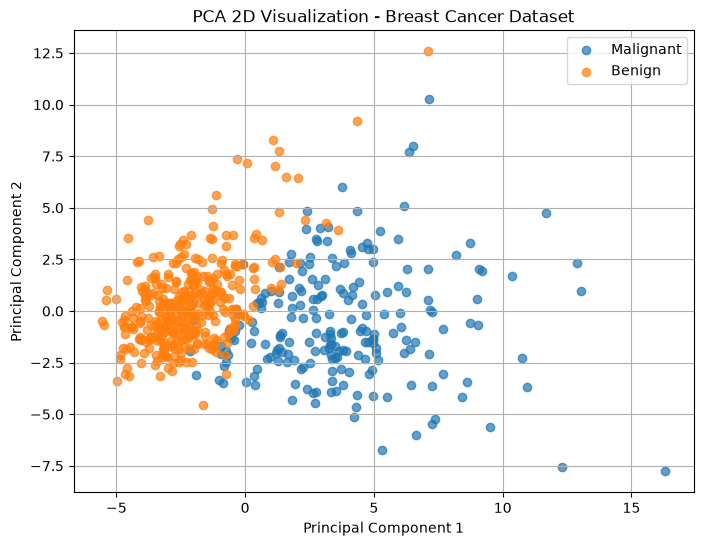

Total variance retained: 63.24 %


In [10]:
import matplotlib.pyplot as plt
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler

# Standardize the data
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# Apply PCA with 2 components
pca_2d = PCA(n_components=2)
X_pca_2d = pca_2d.fit_transform(X_scaled)

# Create DataFrame for visualization
pca_df = pd.DataFrame({
    'PC1': X_pca_2d[:, 0],
    'PC2': X_pca_2d[:, 1],
    'Target': y
})

# Plot PCA
plt.figure(figsize=(8, 6))

for label, name in [(0, 'Malignant'), (1, 'Benign')]:
    subset = pca_df[pca_df['Target'] == label]
    plt.scatter(
        subset['PC1'],
        subset['PC2'],
        label=name,
        alpha=0.7
    )

plt.xlabel('Principal Component 1')
plt.ylabel('Principal Component 2')
plt.title('PCA 2D Visualization - Breast Cancer Dataset')
plt.legend()
plt.grid(True)
plt.show()

# Display explained variance
print(
    "Total variance retained:",
    round(pca_2d.explained_variance_ratio_.sum() * 100, 2),
    "%"
)

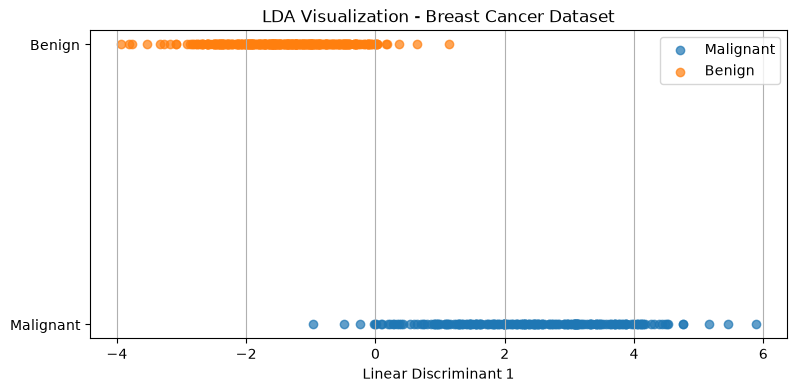

In [11]:
import matplotlib.pyplot as plt
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis
from sklearn.preprocessing import StandardScaler

# Standardize the data
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# Apply LDA with 1 component
lda_1d = LinearDiscriminantAnalysis(n_components=1)
X_lda = lda_1d.fit_transform(X_scaled, y)

# Plot LDA
plt.figure(figsize=(9, 4))

for label, name in [(0, 'Malignant'), (1, 'Benign')]:
    plt.scatter(
        X_lda[y == label, 0],
        np.zeros(sum(y == label)) + label,
        label=name,
        alpha=0.7
    )

plt.xlabel('Linear Discriminant 1')
plt.yticks([0, 1], ['Malignant', 'Benign'])
plt.title('LDA Visualization - Breast Cancer Dataset')
plt.legend()
plt.grid(True, axis='x')
plt.show()